# EDA - Pima Indians Diabetes

768 female patients, 8 measurements, `Outcome` = 1 if diagnosed with diabetes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


## Class balance

Outcome
0    500
1    268
Name: count, dtype: int64
diabetic share: 0.349


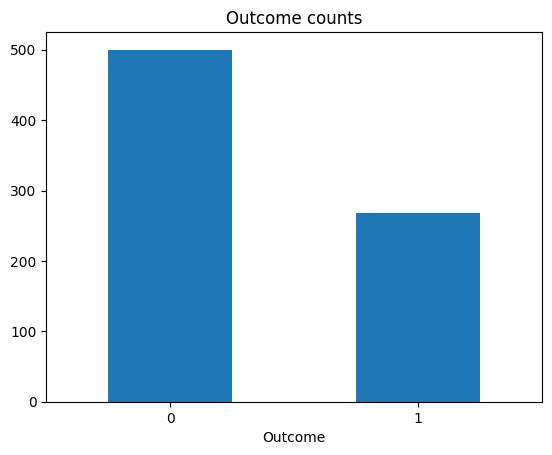

In [3]:
print(df["Outcome"].value_counts())
print("diabetic share:", round(df["Outcome"].mean(), 3))

df["Outcome"].value_counts().plot.bar(rot=0)
plt.title("Outcome counts")
plt.show()

Only about 35% are diabetic, so accuracy alone would be misleading. A model that always predicts 0 already gets ~65%.

## Zeros that are really missing values

Glucose, BloodPressure, SkinThickness, Insulin and BMI all have a min of 0, which isn't possible for a living person. These are missing values. (0 is fine for Pregnancies.)

In [4]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
(df[zero_cols] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Insulin is missing for almost half the rows and SkinThickness for about 30%. I replace these zeros with the median in `src/data.py`.

## Distributions

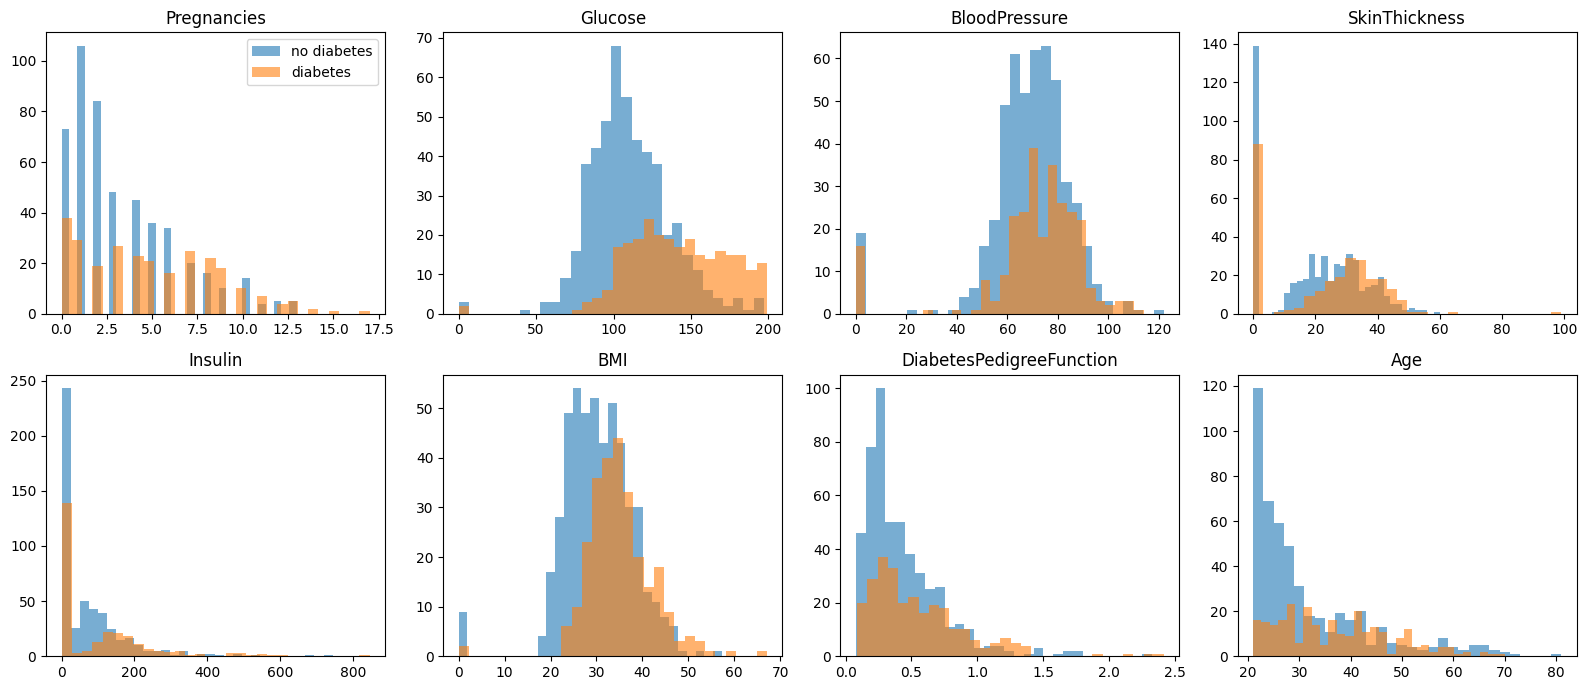

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, df.columns[:-1]):
    ax.hist(df[df.Outcome == 0][col], bins=30, alpha=0.6, label="no diabetes")
    ax.hist(df[df.Outcome == 1][col], bins=30, alpha=0.6, label="diabetes")
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Correlations

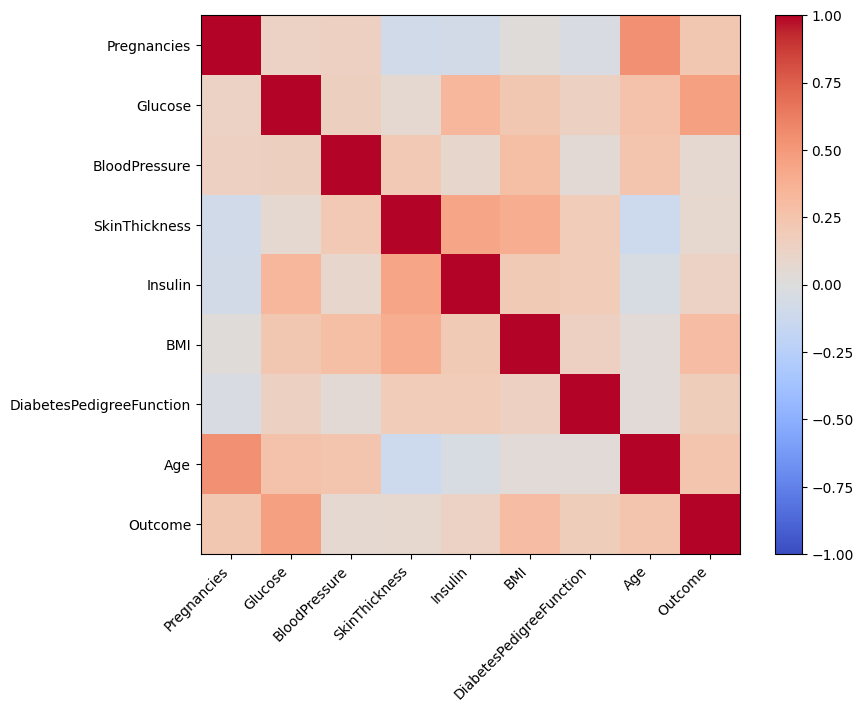

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64

In [6]:
corr = df.corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.show()

corr["Outcome"].sort_values(ascending=False)

## Notes

- Glucose has the strongest link to the outcome, then BMI, Age and Pregnancies.
- Age and Pregnancies are correlated with each other.
- Classes are imbalanced, so I use a stratified split and look at recall, not just accuracy.